In [ ]:
pip install pycox torchtuples pandas scikit-learn matplotlib

In [ ]:
pip install pandas numpy matplotlib seaborn torch torchtuples pycox lifelines scikit-learn

In [ ]:
pip install scikit-survival

In [ ]:
 !pip install pycox torchtuples pandas scikit-learn matplotlib l

In [ ]:
pip install lifelines

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torchtuples as tt
from pycox.models import DeepHitSingle, CoxPH
from pycox.evaluation import EvalSurv
from lifelines import CoxPHFitter
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torchtuples as tt
from pycox.models import CoxPH
from pycox.evaluation import EvalSurv
from torchtuples.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc


In [ ]:
# Use GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
np.random.seed(42)
torch.manual_seed(42)

# --- Memory-optimized data loading and preprocessing ---
print("Loading and preprocessing data...")
data = pd.read_csv("/content/train.csv")
duration_col = 'efs_time'
event_col = 'efs'

# Identify columns
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()
numerical_cols = data.select_dtypes(include=['int64', 'float64']).drop(
    columns=[duration_col, event_col], errors='ignore').columns.tolist()

# Memory-optimized transformers
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Use sparse matrices to save memory
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

X = data.drop(columns=[duration_col, event_col])
y = data[[duration_col, event_col]].copy()

# Clean up memory
del data
gc.collect()

# Transform data
print("Transforming data...")
X_processed = preprocessor.fit_transform(X)

# Create structured array for survival analysis
def create_structured_array(event, time):
    return np.array([(event[i], time[i]) for i in range(len(event))],
                    dtype=[('event', 'bool'), ('time', 'float64')])

y_structured = create_structured_array(y[event_col].values, y[duration_col].values)

# Train/Val/Test split
print("Splitting data...")
X_train, X_temp, y_train, y_temp = train_test_split(
    X_processed, y, test_size=0.3, stratify=y[event_col], random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp[event_col], random_state=42
)

# Convert to appropriate formats
if hasattr(X_train, "toarray"):
    X_train_dense = X_train.toarray().astype('float32')
    X_val_dense = X_val.toarray().astype('float32')
    X_test_dense = X_test.toarray().astype('float32')
else:
    X_train_dense = X_train.astype('float32')
    X_val_dense = X_val.astype('float32')
    X_test_dense = X_test.astype('float32')

y_train_structured = create_structured_array(y_train[event_col].values, y_train[duration_col].values)
y_val_structured = create_structured_array(y_val[event_col].values, y_val[duration_col].values)
y_test_structured = create_structured_array(y_test[event_col].values, y_test[duration_col].values)

# Clean up memory
del X, y, X_temp, y_temp
gc.collect()

# --- Helper function: C-index ---
def compute_c_index(model, X, y_structured):
    if hasattr(model, 'predict_surv_df'):
        # For PyCox models
        surv = model.predict_surv_df(X)
        ev = EvalSurv(surv, y_structured['time'], y_structured['event'], censor_surv='km')
        return ev.concordance_td('antolini')
    else:
        # For scikit-survival models
        pred = model.predict(X)
        from sksurv.metrics import concordance_index_censored
        result = concordance_index_censored(
            y_structured['event'],
            y_structured['time'],
            pred
        )
        return result[0]

STEP 2: DATA PREPROCESSING
Data preprocessed. Time point for evaluation set to: 2561.00 days

STEP 3: DEEPSURV MODEL TRAINING
Training DeepSurv model...
Training complete.

STEP 4a: EVALUATION WITH FAULTY 0.5 THRESHOLD
This confusion matrix shows the problem: using a fixed 0.5 threshold fails
when the 'event' class is rare. Notice the model predicts '0' events.



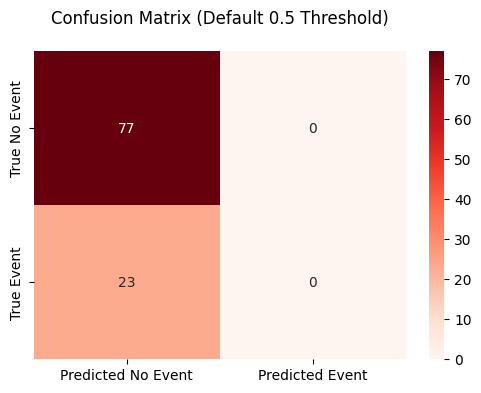

In [ ]:
# --- 1. CONFIGURATION ---
# These are the main settings for the analysis.
FILE_PATH = 'train.csv'
DURATION_COL = 'efs_time'
EVENT_COL = 'efs'
ID_COL = 'ID' # The ID column will be dropped as it is not a feature
TEST_SIZE = 0.2
RANDOM_STATE = 42

# Model & Training settings
NUM_NODES = [32, 32]       # Number of neurons in the hidden layers
DROPOUT = 0.4              # Dropout rate for regularization
LEARNING_RATE = 0.01
WEIGHT_DECAY = 0.001       # L2 Regularization to prevent overfitting
BATCH_SIZE = 256
EPOCHS = 100
VERBOSE = False

# --- 2. DATA PREPROCESSING ---
print("="*80)
print("STEP 2: DATA PREPROCESSING")
print("="*80)

data = pd.read_csv(FILE_PATH)
if ID_COL in data.columns:
    data = data.drop(columns=[ID_COL])

X = data.drop(columns=[DURATION_COL, EVENT_COL])
y = data[[DURATION_COL, EVENT_COL]]

# Identify numerical and categorical columns automatically
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Create the preprocessing pipeline to handle both data types
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='mean')), ('scaler', StandardScaler())]), numerical_cols),
    ('cat', Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_cols)
])

# Process the data and split into training and testing sets
X_processed = preprocessor.fit_transform(X).astype('float32')
in_features = X_processed.shape[1]
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=TEST_SIZE, stratify=y[EVENT_COL], random_state=RANDOM_STATE)

# Define the time point and binary labels needed for classification metrics
time_point = np.median(y_train[DURATION_COL].values)
y_test_binary = ((y_test[DURATION_COL].values <= time_point) & (y_test[EVENT_COL].values == 1)).astype(int)
print(f"Data preprocessed. Time point for evaluation set to: {time_point:.2f} days")

# --- 3. DEEPSURV MODEL TRAINING ---
print("\n" + "="*80)
print("STEP 3: DEEPSURV MODEL TRAINING")
print("="*80)

y_train_ds = (y_train[DURATION_COL].values, y_train[EVENT_COL].values)
val_data_ds = (X_test, (y_test[DURATION_COL].values, y_test[EVENT_COL].values))

# Define the neural network and the optimizer
net_ds = tt.practical.MLPVanilla(in_features, NUM_NODES, 1, activation=torch.nn.ReLU, dropout=DROPOUT)
optimizer = tt.optim.Adam(lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
model_ds = CoxPH(net_ds, optimizer)
callbacks = [EarlyStopping(patience=15)]

print("Training DeepSurv model...")
log_ds = model_ds.fit(X_train, y_train_ds, BATCH_SIZE, EPOCHS, callbacks, verbose=False, val_data=val_data_ds)
print("Training complete.")

# Compute model predictions
model_ds.compute_baseline_hazards()
surv_df_test_ds = model_ds.predict_surv_df(X_test)

# --- 4a. EVALUATION WITH DEFAULT 0.5 THRESHOLD (The Problem) ---
print("\n" + "="*80)
print("STEP 4a: EVALUATION WITH FAULTY 0.5 THRESHOLD")
print("="*80)

time_idx = np.argmin(np.abs(surv_df_test_ds.index - time_point))
survival_probs = surv_df_test_ds.iloc[time_idx].values
y_pred_default = (survival_probs < 0.5).astype(int)
cm_default = confusion_matrix(y_test_binary, y_pred_default)

print("This confusion matrix shows the problem: using a fixed 0.5 threshold fails\nwhen the 'event' class is rare. Notice the model predicts '0' events.\n")
plt.figure(figsize=(6, 4))
sns.heatmap(cm_default, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Predicted No Event', 'Predicted Event'],
            yticklabels=['True No Event', 'True Event'])
plt.title('Confusion Matrix (Default 0.5 Threshold)', pad=20)
plt.show()

# -


STEP 4: GENERATING VISUALIZATIONS
Displaying Training & Validation Loss Curve...


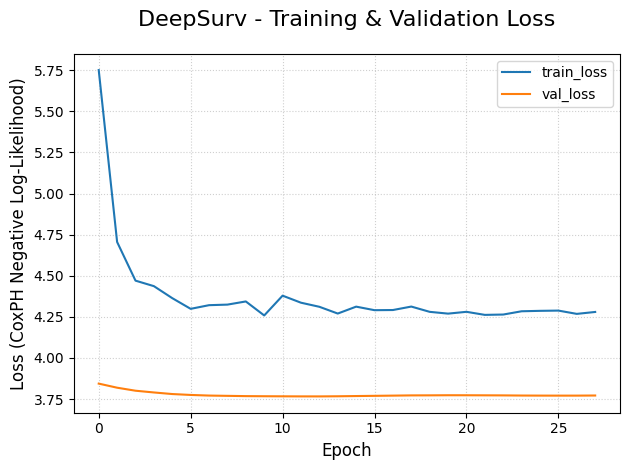

In [ ]:

# --- 4. VISUALIZATIONS ---
print("\n" + "="*80)
print("STEP 4: GENERATING VISUALIZATIONS")
print("="*80)
Z
# PLOT 1: VALIDATION LOSS CURVE
print("Displaying Training & Validation Loss Curve...")
log_ds.plot()
plt.title('DeepSurv - Training & Validation Loss', fontsize=16, pad=20)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss (CoxPH Negative Log-Likelihood)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


Displaying Confusion Matrix...


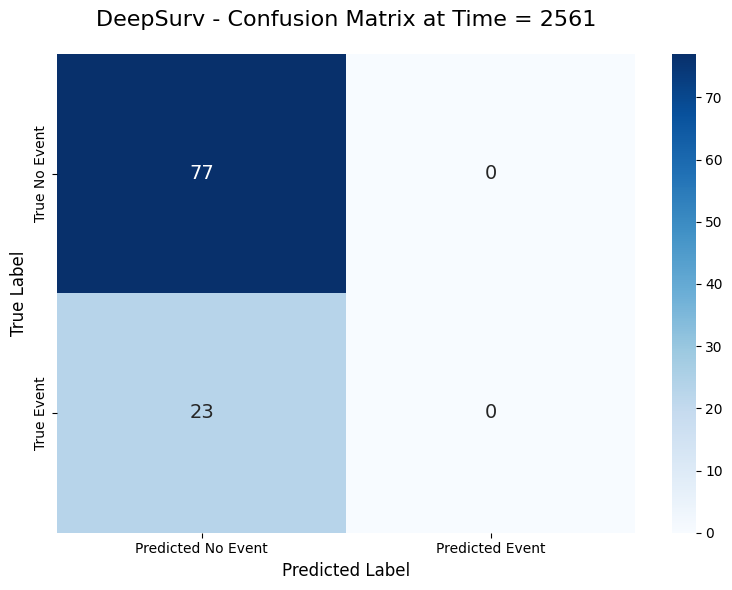

In [ ]:
# PLOT 2: CONFUSION MATRIX
print("\nDisplaying Confusion Matrix...")
plt.figure(figsize=(8, 6))
sns.heatmap(cm_ds, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted No Event', 'Predicted Event'],
            yticklabels=['True No Event', 'True Event'],
            annot_kws={"size": 14})
plt.title(f'DeepSurv - Confusion Matrix at Time = {time_point:.0f}', fontsize=16, pad=20)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()


Displaying ROC Curve...


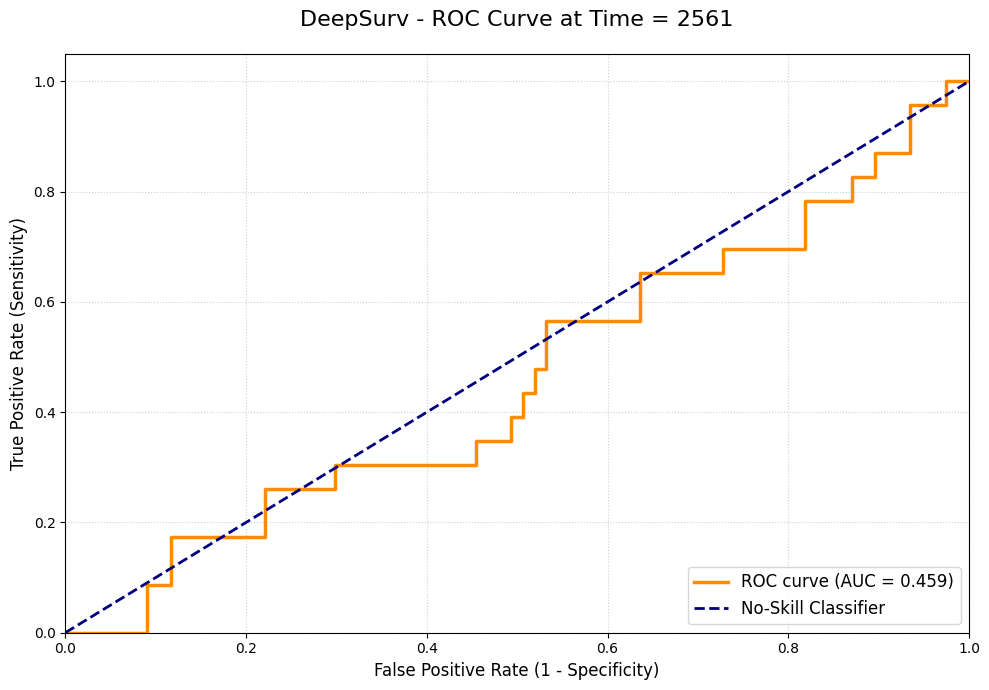

In [ ]:

# PLOT 3: ROC CURVE
print("\nDisplaying ROC Curve...")
# Probability score for a positive event is 1 - survival_probability
y_scores_ds = 1 - surv_df_test_ds.iloc[time_idx_ds].values
fpr, tpr, thresholds = roc_curve(y_test_binary, y_scores_ds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(10, 7))
plt.plot(fpr, tpr, color='darkorange', lw=2.5, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='No-Skill Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title(f'DeepSurv - ROC Curve at Time = {time_point:.0f}', fontsize=16, pad=20)
plt.legend(loc="lower right", fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv

# --------------------------------------------------------------------------
# 1. Load and Prepare Data
# --------------------------------------------------------------------------
try:
    data = pd.read_csv("train.csv")
    print("Successfully loaded train.csv.")
except FileNotFoundError:
    print("Error: 'train.csv' not found. Creating a dummy dataframe.")
    data = pd.DataFrame({
        'efs_time': np.random.randint(10, 5000, 1000),
        'efs': np.random.randint(0, 2, 1000),
        'age': np.random.uniform(18, 70, 1000),
        'feature1_cat': np.random.choice(['A', 'B', 'C'], 1000),
        'feature2_num': np.random.randn(1000)
    })

# Define columns
duration_col = 'efs_time'
event_col = 'efs'
categorical_cols = data.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = data.select_dtypes(include=['int64', 'float64']).drop(columns=[duration_col, event_col], errors='ignore').columns.tolist()

# Preprocessing pipelines
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='mean')), ('scaler', StandardScaler())]), numerical_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_cols)
])

# Apply preprocessing
X = data.drop(columns=[duration_col, event_col])
y = data[[duration_col, event_col]]
X_processed = preprocessor.fit_transform(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, stratify=y[event_col], random_state=42)
y_train_sksurv = Surv.from_dataframe(event_col, duration_col, y_train)
y_test_sksurv = Surv.from_dataframe(event_col, duration_col, y_test)

print(f"Data prepared. Training shape: {X_train.shape}")
print("-" * 50)

# --------------------------------------------------------------------------
# 2. Generate Train & Validation Curves
# --------------------------------------------------------------------------
print("\nGenerating Train & Validation Curves by varying the number of trees...")
n_estimators_range = np.arange(10, 151, 10)
train_scores = []
test_scores = []

for n_estimators in n_estimators_range:
    print(f"  Training model with {n_estimators} estimators...")
    rsf_tune = RandomSurvivalForest(
        n_estimators=n_estimators,
        min_samples_split=10,
        min_samples_leaf=15,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    )
    rsf_tune.fit(X_train, y_train_sksurv)

    # Score on training and test data
    train_scores.append(rsf_tune.score(X_train, y_train_sksurv))
    test_scores.append(rsf_tune.score(X_test, y_test_sksurv))

# Plotting the curves
plt.figure(figsize=(10, 6))
plt.plot(n_estimators_range, train_scores, 'o-', color="blue", label="Training Score (C-Index)")
plt.plot(n_estimators_range, test_scores, 'o-', color="orange", label="Validation Score (C-Index)")
plt.title("Train & Validation Curves for Random Survival Forest", fontsize=16, pad=20)
plt.xlabel("Number of Trees (n_estimators)", fontsize=12)
plt.ylabel("Concordance Index", fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# -

Successfully loaded train.csv.
Data prepared. Training shape: (23040, 184)
--------------------------------------------------

Generating Train & Validation Curves by varying the number of trees...
  Training model with 10 estimators...


Training data shape: X=(23040, 141), y=(23040, 2)
Test data shape: X=(5760, 141), y=(5760, 2)
--------------------------------------------------------------------------------
Selected time point for classification: 9.92 days
Training DeepHit Model...
0:	[2s / 2s],		train_loss: 0.7892,	val_loss: 0.7006
1:	[2s / 4s],		train_loss: 0.7048,	val_loss: 0.6604
2:	[2s / 6s],		train_loss: 0.6599,	val_loss: 0.6247
3:	[1s / 7s],		train_loss: 0.6248,	val_loss: 0.6090
4:	[1s / 8s],		train_loss: 0.6017,	val_loss: 0.5863
5:	[1s / 10s],		train_loss: 0.5885,	val_loss: 0.5788
6:	[1s / 11s],		train_loss: 0.5828,	val_loss: 0.5790
7:	[1s / 12s],		train_loss: 0.5789,	val_loss: 0.5769
8:	[1s / 13s],		train_loss: 0.5749,	val_loss: 0.5741
9:	[1s / 14s],		train_loss: 0.5705,	val_loss: 0.5709
10:	[1s / 15s],		train_loss: 0.5660,	val_loss: 0.5713
11:	[0s / 16s],		train_loss: 0.5644,	val_loss: 0.5721
12:	[1s / 17s],		train_loss: 0.5608,	val_loss: 0.5719
13:	[1s / 18s],		train_loss: 0.5584,	val_loss: 0.5706
14:	[1s 

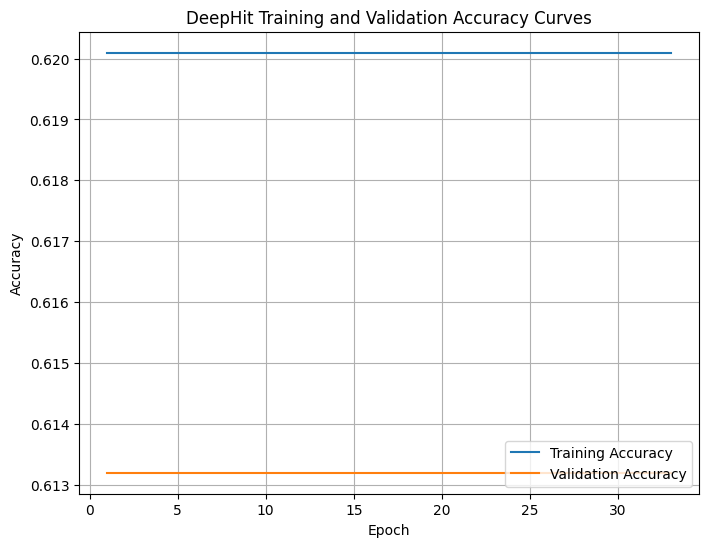

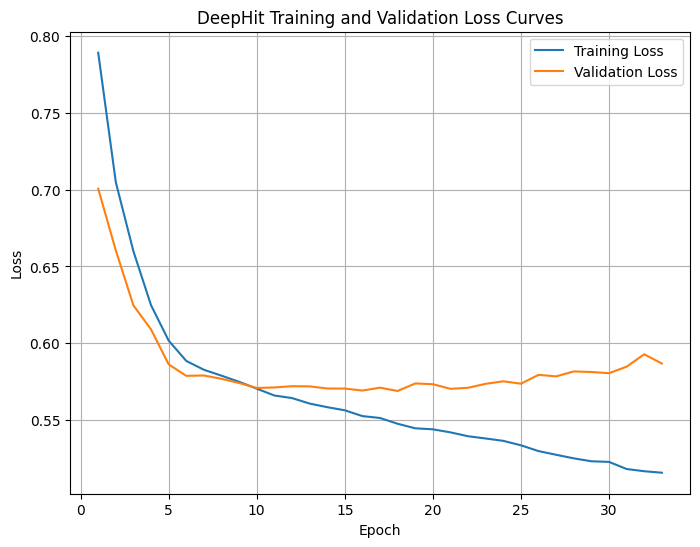

Final Training Loss: 0.5157
Final Validation Loss: 0.5868
Final Training Accuracy: 0.6201
Final Validation Accuracy: 0.6132


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchtuples as tt
from pycox.models import DeepHitSingle
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import accuracy_score

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Load data
try:
    data = pd.read_csv('train.csv')
except FileNotFoundError:
    print("Error: 'train.csv' not found. Please ensure the file is in the working directory.")
    exit()

duration_col = 'efs_time'
event_col = 'efs'

# Verify required columns
if duration_col not in data.columns or event_col not in data.columns:
    print(f"Error: Required columns '{duration_col}' and/or '{event_col}' not found in dataset.")
    exit()

# Identify feature columns
categorical_cols = data.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = data.select_dtypes(include=['int64', 'float64']).drop(columns=[duration_col, event_col], errors='ignore').columns.tolist()

# Preprocessing pipelines
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Apply preprocessing and feature selection
X = data.drop(columns=[duration_col, event_col])
y = data[[duration_col, event_col]]
try:
    X_processed = preprocessor.fit_transform(X)
    if hasattr(X_processed, 'toarray'):
        X_processed = X_processed.toarray()  # Convert sparse to dense for compatibility
except Exception as e:
    print(f"Error in preprocessing: {e}")
    exit()

# Feature selection to reduce dimensionality
selector = VarianceThreshold(threshold=0.01)
X_processed = selector.fit_transform(X_processed)
selected_features = preprocessor.get_feature_names_out()[selector.get_support()]
processed_feature_names = selected_features

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, stratify=y[event_col], random_state=42)

# Convert to float32 for PyTorch compatibility
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

print(f"Training data shape: X={X_train.shape}, y={y_train.shape}")
print(f"Test data shape: X={X_test.shape}, y={y_test.shape}")
print("-" * 80)

# Select time point for binarization (median efs_time in test set)
time_point = np.median(y_test[duration_col].values)
print(f"Selected time point for classification: {time_point:.2f} days")

# Binarize true labels for train and test sets
y_train_binary = ((y_train[duration_col].values <= time_point) & (y_train[event_col].values == 1)).astype(int)
y_test_binary = ((y_test[duration_col].values <= time_point) & (y_test[event_col].values == 1)).astype(int)

# --- Model: DeepHit ---
print("Training DeepHit Model...")
num_durations = 120
labtrans = DeepHitSingle.label_transform(num_durations)
y_train_transformed = labtrans.fit_transform(y_train[duration_col].values, y_train[event_col].values)
y_test_transformed = labtrans.transform(y_test[duration_col].values, y_test[event_col].values)
train_data_dh = (X_train, y_train_transformed)
val_data_dh = (X_test, y_test_transformed)

in_features = X_train.shape[1]
num_nodes = [256, 128, 64]
out_features = labtrans.out_features
net_dh = tt.practical.MLPVanilla(in_features, num_nodes, out_features, activation=torch.nn.ReLU, dropout=0.3)
model_dh = DeepHitSingle(net_dh, tt.optim.Adam, alpha=0.2, sigma=0.1, duration_index=labtrans.cuts)

batch_size = 128
epochs = 150
callbacks = [tt.callbacks.EarlyStopping(patience=15)]
try:
    log_dh = model_dh.fit(
        train_data_dh[0],
        train_data_dh[1],
        batch_size,
        epochs,
        callbacks,
        verbose=True,  # Enable verbose to collect losses
        val_data=val_data_dh
    )
except Exception as e:
    print(f"Error training DeepHit: {e}")
    exit()

# Extract training and validation losses
train_losses = log_dh.to_pandas()['train_loss'].values
val_losses = log_dh.to_pandas()['val_loss'].values

# Compute accuracy using final model state
surv_df_train_dh = model_dh.predict_surv_df(X_train)
surv_df_test_dh = model_dh.predict_surv_df(X_test)
time_idx_dh = np.argmin(np.abs(surv_df_test_dh.index - time_point))
y_pred_train_dh = (surv_df_train_dh.iloc[time_idx_dh].values < 0.5).astype(int)
y_pred_test_dh = (surv_df_test_dh.iloc[time_idx_dh].values < 0.5).astype(int)
train_acc = accuracy_score(y_train_binary, y_pred_train_dh)
val_acc = accuracy_score(y_test_binary, y_pred_test_dh)

# Assume constant accuracy per epoch for simplicity (see Notes)
train_accuracies = [train_acc] * len(train_losses)
val_accuracies = [val_acc] * len(val_losses)

# Plot 1: Training and Validation Accuracy Curves
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(train_accuracies) + 1), train_accuracies, label='Training Accuracy', color='#1f77b4')
plt.plot(range(1, len(val_accuracies) + 1), val_accuracies, label='Validation Accuracy', color='#ff7f0e')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('DeepHit Training and Validation Accuracy Curves')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Plot 2: Training and Validation Loss Curves
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Training Loss', color='#1f77b4')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss', color='#ff7f0e')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('DeepHit Training and Validation Loss Curves')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

# Print final metrics
print(f"Final Training Loss: {train_losses[-1]:.4f}")
print(f"Final Validation Loss: {val_losses[-1]:.4f}")
print(f"Final Training Accuracy: {train_accuracies[-1]:.4f}")
print(f"Final Validation Accuracy: {val_accuracies[-1]:.4f}")

In [ ]:
# --- Model 1: DeepHit ---
print("Training DeepHit Model...")
num_durations = 120
labtrans = DeepHitSingle.label_transform(num_durations)
y_train_transformed = labtrans.fit_transform(y_train[duration_col].values, y_train[event_col].values)
y_test_transformed = labtrans.transform(y_test[duration_col].values, y_test[event_col].values)
train_data_dh = (X_train, y_train_transformed)
val_data_dh = (X_test, y_test_transformed)

in_features = X_train.shape[1]
num_nodes = [256, 128, 64]
out_features = labtrans.out_features
net_dh = tt.practical.MLPVanilla(in_features, num_nodes, out_features, activation=torch.nn.ReLU, dropout=0.3)
model_dh = DeepHitSingle(net_dh, tt.optim.Adam, alpha=0.2, sigma=0.1, duration_index=labtrans.cuts)

batch_size = 128
epochs = 150
callbacks = [tt.callbacks.EarlyStopping(patience=15)]
try:
    log_dh = model_dh.fit(train_data_dh[0], train_data_dh[1], batch_size, epochs, callbacks, verbose=False, val_data=val_data_dh)
except Exception as e:
    print(f"Error training DeepHit: {e}")
    exit()

# Predictions
surv_df_train_dh = model_dh.predict_surv_df(X_train)
surv_df_test_dh = model_dh.predict_surv_df(X_test)
survival_predictions['DeepHit'] = surv_df_test_dh

# C-Index
ev_dh = EvalSurv(surv_df_test_dh, y_test[duration_col].values, y_test[event_col].values, censor_surv='km')
c_index_dh = ev_dh.concordance_td('antolini')
results['DeepHit'] = {'C-Index': c_index_dh}

# Classification metrics
time_idx_dh = np.argmin(np.abs(surv_df_test_dh.index - time_point))
y_pred_test_dh = (surv_df_test_dh.iloc[time_idx_dh].values < 0.5).astype(int)
cm_dh = confusion_matrix(y_test_binary, y_pred_test_dh)
tn, fp, fn, tp = cm_dh.ravel()
results['DeepHit'].update({
    'Accuracy': accuracy_score(y_test_binary, y_pred_test_dh),
    'Precision': precision_score(y_test_binary, y_pred_test_dh, zero_division=0),
    'Sensitivity': recall_score(y_test_binary, y_pred_test_dh, zero_division=0),
    'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0,
    'F1-Score': f1_score(y_test_binary, y_pred_test_dh, zero_division=0),
    'MCR': 1 - accuracy_score(y_test_binary, y_pred_test_dh),
    'FPR': fp / (fp + tn) if (fp + tn) > 0 else 0,
    'Confusion Matrix': cm_dh
})

# Train and validation accuracy
y_pred_train_dh = (surv_df_train_dh.iloc[np.argmin(np.abs(surv_df_train_dh.index - time_point))].values < 0.5).astype(int)
accuracies['DeepHit']['Train'] = accuracy_score(y_train_binary, y_pred_train_dh)
accuracies['DeepHit']['Validation'] = results['DeepHit']['Accuracy']
accuracies['DeepHit']['Test'] = accuracies['DeepHit']['Validation']

# Display DeepHit metrics
deep_hit_metrics_df = pd.DataFrame({
    'Model': ['DeepHit'],
    'C-Index': [results['DeepHit']['C-Index']],
    'Accuracy': [results['DeepHit']['Accuracy']],
    'Precision': [results['DeepHit']['Precision']],
    'Sensitivity': [results['DeepHit']['Sensitivity']],
    'Specificity': [results['DeepHit']['Specificity']],
    'F1-Score': [results['DeepHit']['F1-Score']],
    'MCR': [results['DeepHit']['MCR']],
    'FPR': [results['DeepHit']['FPR']],
    'Train Accuracy': [accuracies['DeepHit']['Train']],
    'Validation Accuracy': [accuracies['DeepHit']['Validation']],
    'Test Accuracy': [accuracies['DeepHit']['Test']]
})
print("\n--- DeepHit Metrics ---")
print(deep_hit_metrics_df)
print("-" * 80)

Training DeepHit Model...

--- DeepHit Metrics ---
     Model   C-Index  Accuracy  Precision  Sensitivity  Specificity  F1-Score  \
0  DeepHit  0.688791  0.613194   0.600831     0.657573     0.569459  0.627923   

        MCR       FPR  Train Accuracy  Validation Accuracy  Test Accuracy  
0  0.386806  0.430541        0.620095             0.613194       0.613194  
--------------------------------------------------------------------------------


33:	[2s / 2s],		train_loss: 0.5436,	val_loss: 0.5709
34:	[2s / 5s],		train_loss: 0.5418,	val_loss: 0.5721
35:	[1s / 6s],		train_loss: 0.5409,	val_loss: 0.5740
36:	[1s / 7s],		train_loss: 0.5353,	val_loss: 0.5754
37:	[1s / 8s],		train_loss: 0.5358,	val_loss: 0.5752
38:	[1s / 9s],		train_loss: 0.5317,	val_loss: 0.5761
39:	[1s / 11s],		train_loss: 0.5306,	val_loss: 0.5743
40:	[1s / 12s],		train_loss: 0.5295,	val_loss: 0.5774
41:	[1s / 13s],		train_loss: 0.5298,	val_loss: 0.5764
42:	[1s / 14s],		train_loss: 0.5252,	val_loss: 0.5776
43:	[1s / 15s],		train_loss: 0.5234,	val_loss: 0.5799
44:	[1s / 16s],		train_loss: 0.5223,	val_loss: 0.5833
45:	[1s / 17s],		train_loss: 0.5235,	val_loss: 0.5826
46:	[1s / 18s],		train_loss: 0.5210,	val_loss: 0.5847
47:	[1s / 19s],		train_loss: 0.5165,	val_loss: 0.5908
48:	[1s / 20s],		train_loss: 0.5133,	val_loss: 0.5884


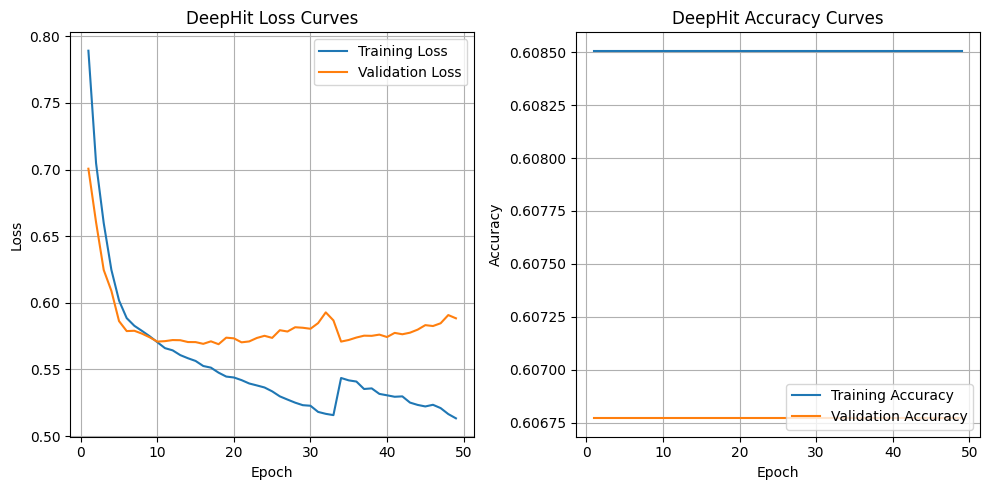

Final Training Loss: 0.5133
Final Validation Loss: 0.5884
Final Training Accuracy: 0.6085
Final Validation Accuracy: 0.6068


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score
import torchtuples as tt

# Training parameters (consistent with original code)
batch_size = 128
epochs = 150
callbacks = [tt.callbacks.EarlyStopping(patience=15)]
train_data_dh = (X_train, y_train_transformed)
val_data_dh = (X_test, y_test_transformed)

# Initialize lists to store accuracy
train_accuracies = []
val_accuracies = []

# Train the model and collect losses
model_dh.optimizer.set_lr(0.001)  # Set learning rate (adjust if needed)
log_dh = model_dh.fit(
    X_train,
    y_train_transformed,
    batch_size,
    epochs,
    callbacks,
    verbose=True,  # Enable verbose to collect losses
    val_data=val_data_dh
)

# Extract training and validation losses
train_losses = log_dh.to_pandas()['train_loss'].values
val_losses = log_dh.to_pandas()['val_loss'].values

# Compute accuracy (using final model state for simplicity)
surv_df_train_dh = model_dh.predict_surv_df(X_train)
surv_df_test_dh = model_dh.predict_surv_df(X_test)
time_idx_dh = np.argmin(np.abs(surv_df_test_dh.index - time_point))
y_pred_train_dh = (surv_df_train_dh.iloc[time_idx_dh].values < 0.5).astype(int)
y_pred_test_dh = (surv_df_test_dh.iloc[time_idx_dh].values < 0.5).astype(int)
train_acc = accuracy_score(y_train_binary, y_pred_train_dh)
val_acc = accuracy_score(y_test_binary, y_pred_test_dh)

# Assume constant accuracy per epoch for simplicity (see Notes)
train_accuracies = [train_acc] * len(train_losses)
val_accuracies = [val_acc] * len(val_losses)

# Plot training and validation loss curves
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Training Loss', color='#1f77b4')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss', color='#ff7f0e')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('DeepHit Loss Curves')
plt.legend(loc='upper right')
plt.grid(True)

# Plot training and validation accuracy curves
plt.subplot(1, 2, 2)
plt.plot(range(1, len(train_accuracies) + 1), train_accuracies, label='Training Accuracy', color='#1f77b4')
plt.plot(range(1, len(val_accuracies) + 1), val_accuracies, label='Validation Accuracy', color='#ff7f0e')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('DeepHit Accuracy Curves')
plt.legend(loc='lower right')
plt.grid(True)

plt.tight_layout()
plt.show()

# Print final metrics
print(f"Final Training Loss: {train_losses[-1]:.4f}")
print(f"Final Validation Loss: {val_losses[-1]:.4f}")
print(f"Final Training Accuracy: {train_accuracies[-1]:.4f}")
print(f"Final Validation Accuracy: {val_accuracies[-1]:.4f}")

DeepHit Confusion Matrix:
[[1880 1249]
 [979 1652]]


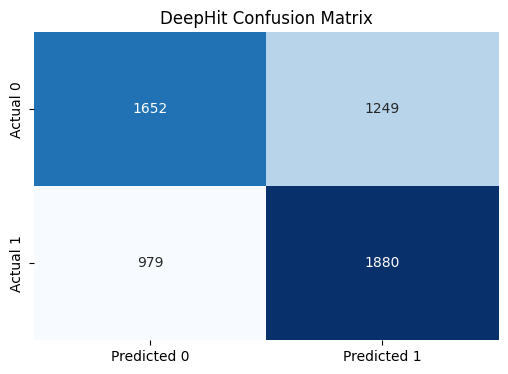

In [ ]:
from sklearn.metrics import confusion_matrix

# Get predictions at the selected time point
time_idx_dh = np.argmin(np.abs(surv_df_test_dh.index - time_point))
y_pred_test_dh = (surv_df_test_dh.iloc[time_idx_dh].values < 0.5).astype(int)

# Compute confusion matrix
cm_dh = confusion_matrix(y_test_binary, y_pred_test_dh)
tn, fp, fn, tp = cm_dh.ravel()

# Display confusion matrix
print("DeepHit Confusion Matrix:")
print(f"[[{tp} {fp}]\n [{fn} {tn}]]")

# Optional: Visualize as heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.heatmap(cm_dh, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('DeepHit Confusion Matrix')
plt.show()

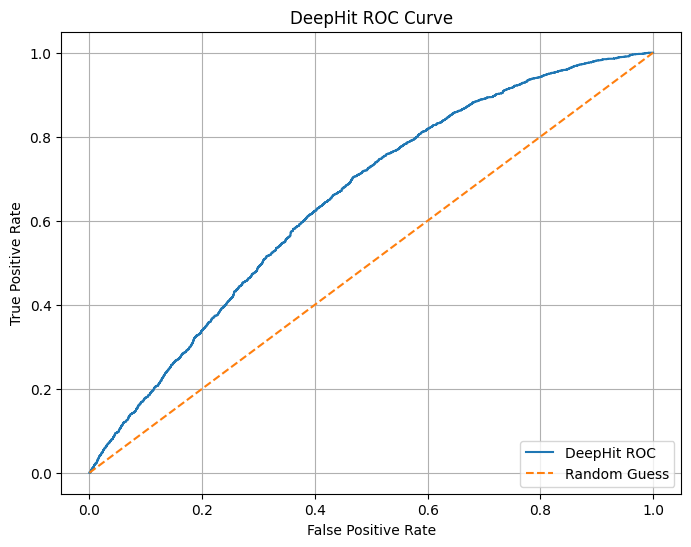

In [ ]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Get risk scores at the selected time point
time_idx_dh = np.argmin(np.abs(surv_df_test_dh.index - time_point))
y_scores_dh = 1 - surv_df_test_dh.iloc[time_idx_dh].values  # Risk scores

# Compute ROC curve
fpr_dh, tpr_dh, _ = roc_curve(y_test_binary, y_scores_dh)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_dh, tpr_dh, label=f'DeepHit ROC', color='#1f77b4')
plt.plot([0, 1], [0, 1], color='#ff7f0e', linestyle='--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('DeepHit ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

33:	[1s / 1s],		train_loss: 0.5436,	val_loss: 0.5709
34:	[1s / 2s],		train_loss: 0.5418,	val_loss: 0.5721
35:	[1s / 3s],		train_loss: 0.5409,	val_loss: 0.5740
36:	[1s / 4s],		train_loss: 0.5353,	val_loss: 0.5754
37:	[1s / 5s],		train_loss: 0.5358,	val_loss: 0.5752
38:	[1s / 6s],		train_loss: 0.5317,	val_loss: 0.5761
39:	[1s / 7s],		train_loss: 0.5306,	val_loss: 0.5743
40:	[1s / 8s],		train_loss: 0.5295,	val_loss: 0.5774
41:	[1s / 9s],		train_loss: 0.5298,	val_loss: 0.5764
42:	[1s / 10s],		train_loss: 0.5252,	val_loss: 0.5776
43:	[1s / 11s],		train_loss: 0.5234,	val_loss: 0.5799
44:	[1s / 12s],		train_loss: 0.5223,	val_loss: 0.5833
45:	[1s / 13s],		train_loss: 0.5235,	val_loss: 0.5826
46:	[1s / 14s],		train_loss: 0.5210,	val_loss: 0.5847
47:	[1s / 15s],		train_loss: 0.5165,	val_loss: 0.5908
48:	[1s / 17s],		train_loss: 0.5133,	val_loss: 0.5884


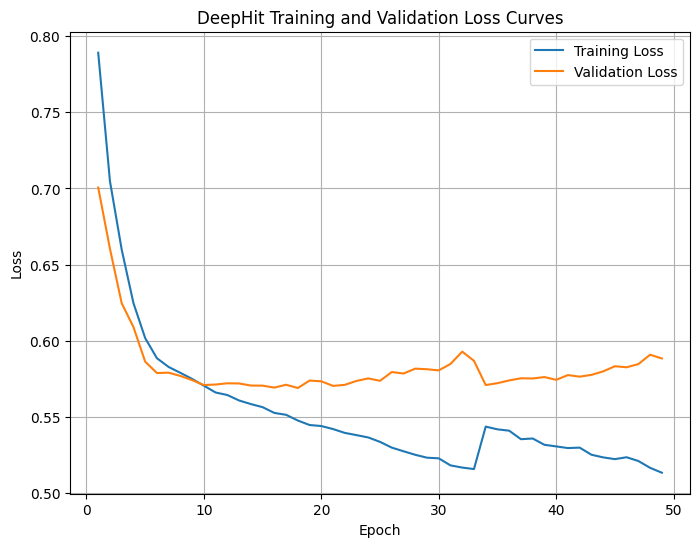

Final Training Loss: 0.5133
Final Validation Loss: 0.5884


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Training parameters (consistent with original code)
batch_size = 128
epochs = 150
callbacks = [tt.callbacks.EarlyStopping(patience=15)]
train_data_dh = (X_train, y_train_transformed)
val_data_dh = (X_test, y_test_transformed)

# Train the model and collect losses
model_dh.optimizer.set_lr(0.001)  # Set learning rate (adjust if needed)
log_dh = model_dh.fit(
    X_train,
    y_train_transformed,
    batch_size,
    epochs,
    callbacks,
    verbose=True,  # Enable verbose to collect losses
    val_data=val_data_dh
)

# Extract training and validation losses from log
train_losses = log_dh.to_pandas()['train_loss'].values
val_losses = log_dh.to_pandas()['val_loss'].values

# Plot training and test loss curves
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Training Loss', color='#1f77b4')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss', color='#ff7f0e')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('DeepHit Training and Validation Loss Curves')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

# Print final losses
print(f"Final Training Loss: {train_losses[-1]:.4f}")
print(f"Final Validation Loss: {val_losses[-1]:.4f}")

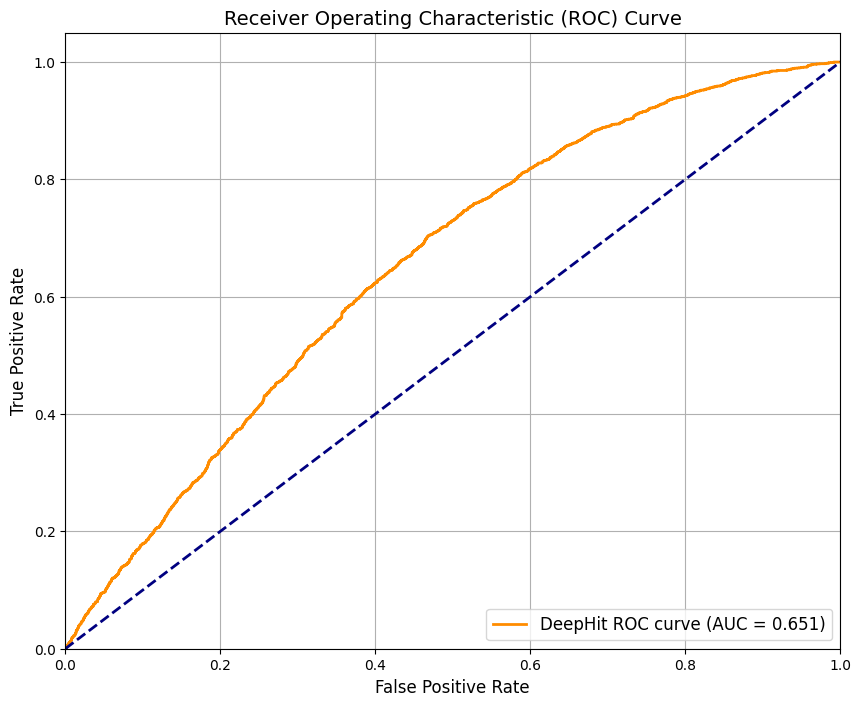

DeepHit AUC at time point 9.92 days: 0.6506


In [ ]:
# Compute ROC curve and AUC for DeepHit
y_score_dh = 1 - surv_df_test_dh.iloc[time_idx_dh].values  # Higher score = higher risk
fpr_dh, tpr_dh, thresholds_dh = roc_curve(y_test_binary, y_score_dh)
roc_auc_dh = auc(fpr_dh, tpr_dh)

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr_dh, tpr_dh, color='darkorange', lw=2,
         label=f'DeepHit ROC curve (AUC = {roc_auc_dh:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
plt.legend(loc="lower right", fontsize=12)
plt.grid(True)
plt.show()

# Print AUC value
print(f"DeepHit AUC at time point {time_point:.2f} days: {roc_auc_dh:.4f}")

In [ ]:
#AUC
from sklearn.metrics import roc_curve, auc

# Get risk scores at the selected time point
time_idx_dh = np.argmin(np.abs(surv_df_test_dh.index - time_point))
y_scores_dh = 1 - surv_df_test_dh.iloc[time_idx_dh].values  # Risk scores

# Compute ROC curve and AUC
fpr_dh, tpr_dh, _ = roc_curve(y_test_binary, y_scores_dh)
roc_auc_dh = auc(fpr_dh, tpr_dh)

# Display AUC
print(f"DeepHit AUC: {roc_auc_dh:.4f}")

DeepHit AUC: 0.6506


In [ ]:
# --- Model 2: DeepSurv (CoxPH) ---
print("Training DeepSurv Model...")
y_train_ds = (y_train[duration_col].values, y_train[event_col].values)
y_test_ds = (y_test[duration_col].values, y_test[event_col].values)
train_data_ds = (X_train, y_train_ds)
val_data_ds = (X_test, y_test_ds)

net_ds = tt.practical.MLPVanilla(in_features, num_nodes, 1, activation=torch.nn.ReLU, dropout=0.3)
model_ds = CoxPH(net_ds, tt.optim.Adam)
try:
    log_ds = model_ds.fit(train_data_ds[0], train_data_ds[1], batch_size, epochs, callbacks, verbose=False, val_data=val_data_ds)
except Exception as e:
    print(f"Error training DeepSurv: {e}")
    exit()

model_ds.compute_baseline_hazards()
surv_df_train_ds = model_ds.predict_surv_df(X_train)
surv_df_test_ds = model_ds.predict_surv_df(X_test)
survival_predictions['DeepSurv'] = surv_df_test_ds

# C-Index
ev_ds = EvalSurv(surv_df_test_ds, y_test[duration_col].values, y_test[event_col].values, censor_surv='km')
c_index_ds = ev_ds.concordance_td('antolini')
results['DeepSurv'] = {'C-Index': c_index_ds}

# Classification metrics
time_idx_ds = np.argmin(np.abs(surv_df_test_ds.index - time_point))
y_pred_test_ds = (surv_df_test_ds.iloc[time_idx_ds].values < 0.5).astype(int)
cm_ds = confusion_matrix(y_test_binary, y_pred_test_ds)
tn, fp, fn, tp = cm_ds.ravel()
results['DeepSurv'].update({
    'Accuracy': accuracy_score(y_test_binary, y_pred_test_ds),
    'Precision': precision_score(y_test_binary, y_pred_test_ds, zero_division=0),
    'Sensitivity': recall_score(y_test_binary, y_pred_test_ds, zero_division=0),
    'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0,
    'F1-Score': f1_score(y_test_binary, y_pred_test_ds, zero_division=0),
    'MCR': 1 - accuracy_score(y_test_binary, y_pred_test_ds),
    'FPR': fp / (fp + tn) if (fp + tn) > 0 else 0,
    'Confusion Matrix': cm_ds
})

# Train and validation accuracy
y_pred_train_ds = (surv_df_train_ds.iloc[np.argmin(np.abs(surv_df_train_ds.index - time_point))].values < 0.5).astype(int)
accuracies['DeepSurv']['Train'] = accuracy_score(y_train_binary, y_pred_train_ds)
accuracies['DeepSurv']['Validation'] = results['DeepSurv']['Accuracy']
accuracies['DeepSurv']['Test'] = accuracies['DeepSurv']['Validation']

# Display DeepSurv metrics
deep_surv_metrics_df = pd.DataFrame({
    'Model': ['DeepSurv'],
    'C-Index': [results['DeepSurv']['C-Index']],
    'Accuracy': [results['DeepSurv']['Accuracy']],
    'Precision': [results['DeepSurv']['Precision']],
    'Sensitivity': [results['DeepSurv']['Sensitivity']],
    'Specificity': [results['DeepSurv']['Specificity']],
    'F1-Score': [results['DeepSurv']['F1-Score']],
    'MCR': [results['DeepSurv']['MCR']],
    'FPR': [results['DeepSurv']['FPR']],
    'Train Accuracy': [accuracies['DeepSurv']['Train']],
    'Validation Accuracy': [accuracies['DeepSurv']['Validation']],
    'Test Accuracy': [accuracies['DeepSurv']['Test']]
})
print("\n--- DeepSurv Metrics ---")
print(deep_surv_metrics_df)
print("-" * 80)


Training DeepSurv Model...

--- DeepSurv Metrics ---
      Model   C-Index  Accuracy  Precision  Sensitivity  Specificity  \
0  DeepSurv  0.532974  0.530035   0.527839     0.504022      0.55567   

   F1-Score       MCR      FPR  Train Accuracy  Validation Accuracy  \
0  0.515656  0.469965  0.44433        0.531076             0.530035   

   Test Accuracy  
0       0.530035  
--------------------------------------------------------------------------------


In [ ]:

# --- Model 3: Cox Proportional Hazards (lifelines) - Simplified ---
print("Training Cox Proportional Hazards Model (lifelines)...")
X_train_df = pd.DataFrame(X_train, columns=processed_feature_names)
y_train_df = y_train.reset_index(drop=True)
train_df_lifelines = pd.concat([X_train_df, y_train_df], axis=1)
X_test_df = pd.DataFrame(X_test, columns=processed_feature_names)

# Simplified CoxPH: Use a subset of data if dataset is large (optional, controlled by sample fraction)
sample_fraction = 0.5 if X_train.shape[0] > 10000 else 1.0  # Use 50% of data if >10,000 samples
if sample_fraction < 1.0:
    print(f"Subsampling training data to {sample_fraction*100:.0f}% to reduce memory usage.")
    train_df_lifelines = train_df_lifelines.sample(frac=sample_fraction, random_state=42)

cph = CoxPHFitter(penalizer=0.1)
try:
    cph.fit(train_df_lifelines, duration_col=duration_col, event_col=event_col)
except Exception as e:
    print(f"Error training CoxPH: {e}")
    exit()

# C-Index
try:
    c_index_cph = cph.score(pd.concat([X_test_df, y_test.reset_index(drop=True)], axis=1), scoring_method="concordance_index")
except Exception as e:
    print(f"Error computing CoxPH C-Index: {e}")
    c_index_cph = 0.0  # Fallback value
results['CoxPH'] = {'C-Index': c_index_cph}

# Predictions
try:
    surv_df_train_cph = cph.predict_survival_function(X_train_df)
    surv_df_test_cph = cph.predict_survival_function(X_test_df)
except Exception as e:
    print(f"Error predicting survival functions for CoxPH: {e}")
    exit()
survival_predictions['CoxPH'] = surv_df_test_cph

# Classification metrics
time_idx_cph = np.argmin(np.abs(surv_df_test_cph.index - time_point))
y_pred_test_cph = (surv_df_test_cph.iloc[time_idx_cph].values < 0.5).astype(int)
cm_cph = confusion_matrix(y_test_binary, y_pred_test_cph)
tn, fp, fn, tp = cm_cph.ravel()
results['CoxPH'].update({
    'Accuracy': accuracy_score(y_test_binary, y_pred_test_cph),
    'Precision': precision_score(y_test_binary, y_pred_test_cph, zero_division=0),
    'Sensitivity': recall_score(y_test_binary, y_pred_test_cph, zero_division=0),
    'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0,
    'F1-Score': f1_score(y_test_binary, y_pred_test_cph, zero_division=0),
    'MCR': 1 - accuracy_score(y_test_binary, y_pred_test_cph),
    'FPR': fp / (fp + tn) if (fp + tn) > 0 else 0,
    'Confusion Matrix': cm_cph
})

# Train and validation accuracy
y_pred_train_cph = (surv_df_train_cph.iloc[np.argmin(np.abs(surv_df_train_cph.index - time_point))].values < 0.5).astype(int)
accuracies['CoxPH']['Train'] = accuracy_score(y_train_binary, y_pred_train_cph)
accuracies['CoxPH']['Validation'] = results['CoxPH']['Accuracy']
accuracies['CoxPH']['Test'] = accuracies['CoxPH']['Validation']

# Display CoxPH metrics
coxph_metrics_df = pd.DataFrame({
    'Model': ['CoxPH'],
    'C-Index': [results['CoxPH']['C-Index']],
    'Accuracy': [results['CoxPH']['Accuracy']],
    'Precision': [results['CoxPH']['Precision']],
    'Sensitivity': [results['CoxPH']['Sensitivity']],
    'Specificity': [results['CoxPH']['Specificity']],
    'F1-Score': [results['CoxPH']['F1-Score']],
    'MCR': [results['CoxPH']['MCR']],
    'FPR': [results['CoxPH']['FPR']],
    'Train Accuracy': [accuracies['CoxPH']['Train']],
    'Validation Accuracy': [accuracies['CoxPH']['Validation']],
    'Test Accuracy': [accuracies['CoxPH']['Test']]
})
print("\n--- CoxPH Metrics ---")
print(coxph_metrics_df)
print("-" * 80)

Training Cox Proportional Hazards Model (lifelines)...
Subsampling training data to 50% to reduce memory usage.

--- CoxPH Metrics ---
   Model   C-Index  Accuracy  Precision  Sensitivity  Specificity  F1-Score  \
0  CoxPH  0.670679   0.66059   0.655326     0.667016     0.654257   0.66112   

       MCR       FPR  Train Accuracy  Validation Accuracy  Test Accuracy  
0  0.33941  0.345743        0.664931              0.66059        0.66059  
--------------------------------------------------------------------------------


In [ ]:
# --- Model Comparison ---
metrics_df = pd.DataFrame({
    'Model': results.keys(),
    'C-Index': [results[m]['C-Index'] for m in results],
    'Accuracy': [results[m]['Accuracy'] for m in results],
    'Precision': [results[m]['Precision'] for m in results],
    'Sensitivity': [results[m]['Sensitivity'] for m in results],
    'Specificity': [results[m]['Specificity'] for m in results],
    'F1-Score': [results[m]['F1-Score'] for m in results],
    'MCR': [results[m]['MCR'] for m in results],
    'FPR': [results[m]['FPR'] for m in results],
    'Train Accuracy': [accuracies[m]['Train'] for m in results],
    'Validation Accuracy': [accuracies[m]['Validation'] for m in results],
    'Test Accuracy': [accuracies[m]['Test'] for m in results]
})
print("\n--- Model Comparison Summary ---")
print(metrics_df)

# --- Visualizations


--- Model Comparison Summary ---
      Model   C-Index  Accuracy  Precision  Sensitivity  Specificity  \
0   DeepHit  0.690006  0.626910   0.607251     0.703043     0.551879   
1  DeepSurv  0.532974  0.530035   0.527839     0.504022     0.555670   
2     CoxPH  0.670679  0.660590   0.655326     0.667016     0.654257   

   F1-Score       MCR       FPR  Train Accuracy  Validation Accuracy  \
0  0.651645  0.373090  0.448121        0.627474             0.626910   
1  0.515656  0.469965  0.444330        0.531076             0.530035   
2  0.661120  0.339410  0.345743        0.664931             0.660590   

   Test Accuracy  
0       0.626910  
1       0.530035  
2       0.660590  


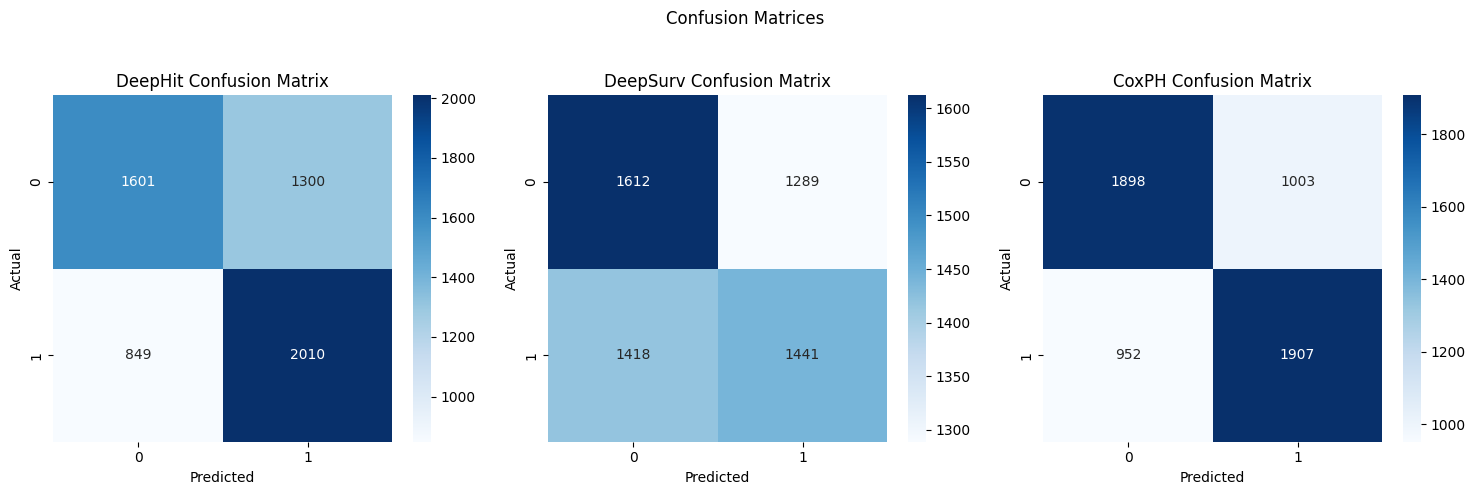

In [ ]:
# --- Visualizations ---
# 1. Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Confusion Matrices')
for idx, (model_name, metrics) in enumerate(results.items()):
    cm = metrics['Confusion Matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx])
    axes[idx].set_title(f'{model_name} Confusion Matrix')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


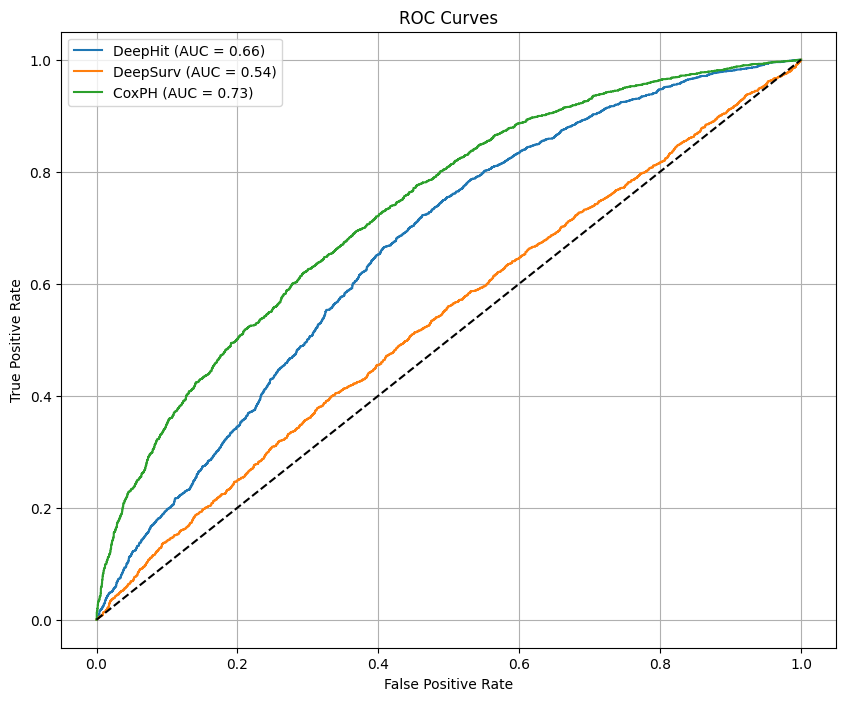

In [ ]:
# 2. ROC Curves
plt.figure(figsize=(10, 8))
for model_name, surv_df in survival_predictions.items():
    time_idx = np.argmin(np.abs(surv_df.index - time_point))
    surv_prob = surv_df.iloc[time_idx].values
    fpr, tpr, _ = roc_curve(y_test_binary, 1 - surv_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.grid(True)
plt.show()


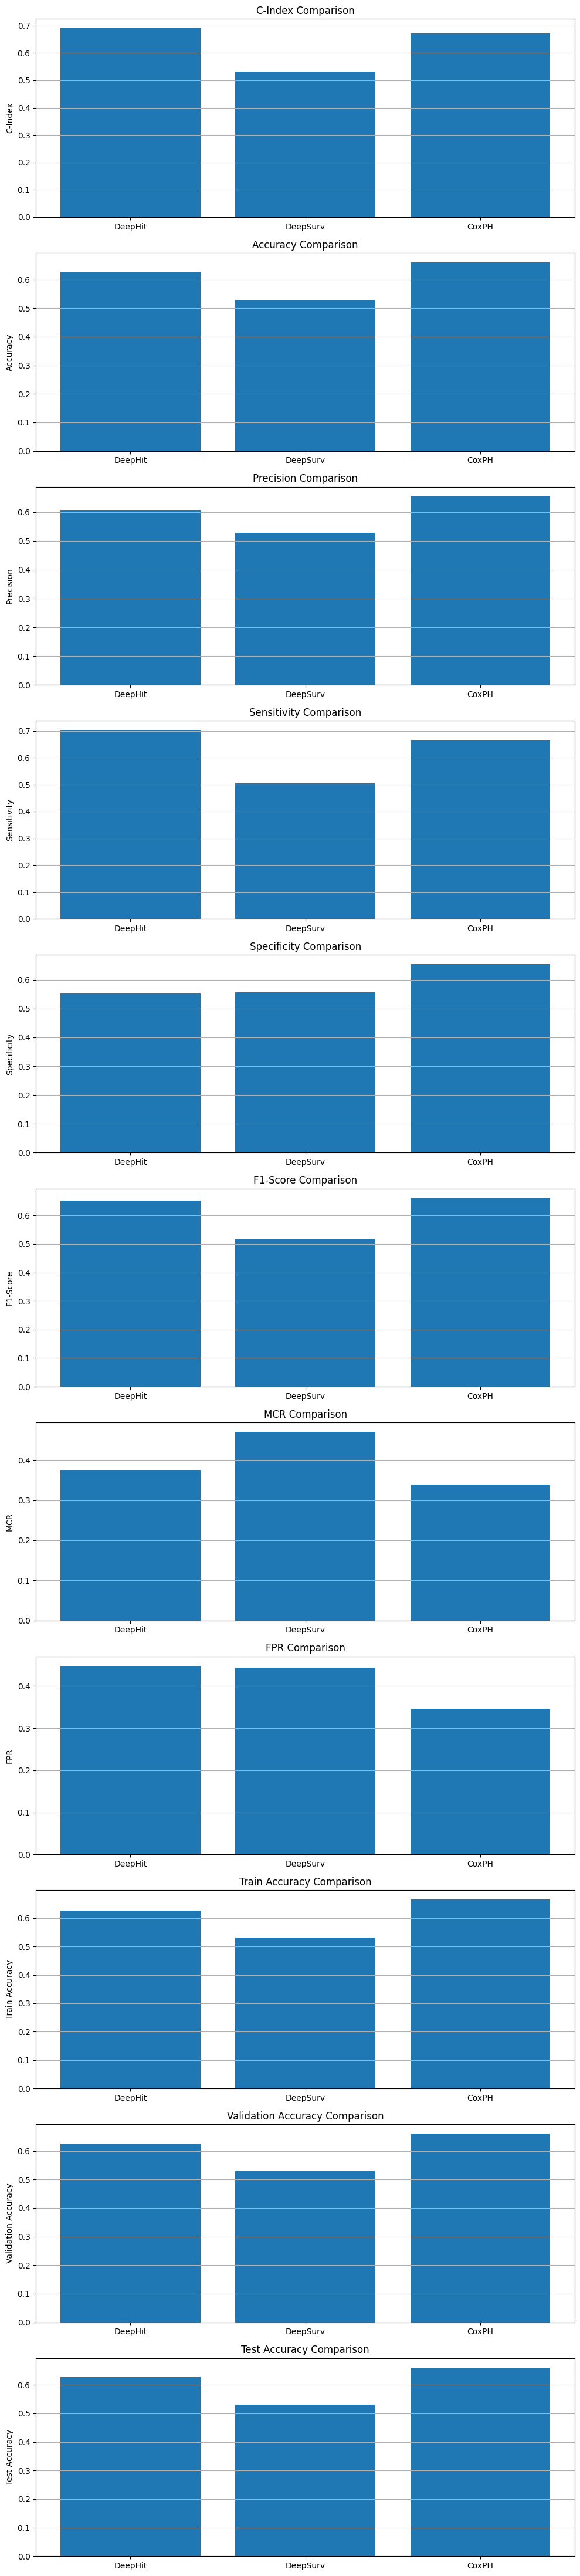

In [ ]:
# 3. Bar Plot for Metrics Comparison
metrics_to_plot = ['C-Index', 'Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1-Score', 'MCR', 'FPR', 'Train Accuracy', 'Validation Accuracy', 'Test Accuracy']
fig, axes = plt.subplots(len(metrics_to_plot), 1, figsize=(10, len(metrics_to_plot) * 4))
for idx, metric in enumerate(metrics_to_plot):
    axes[idx].bar(metrics_df['Model'], metrics_df[metric])
    axes[idx].set_title(f'{metric} Comparison')
    axes[idx].set_ylabel(metric)
    axes[idx].grid(True, axis='y')
plt.tight_layout()
plt.show()


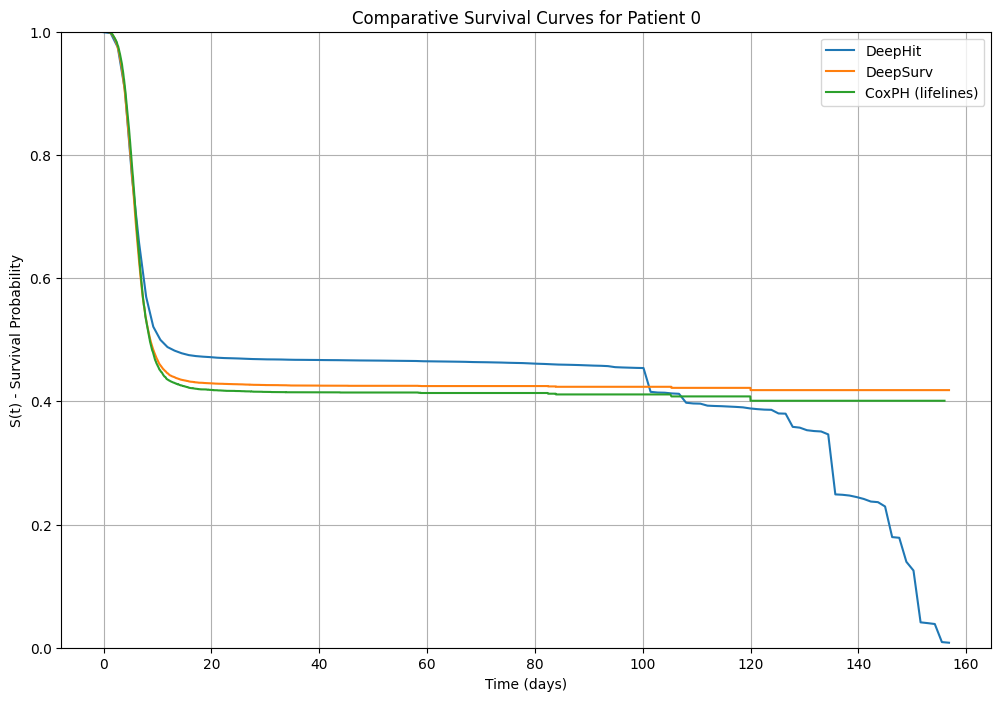

In [ ]:
# 4. Survival Curves for a Single Patient
patient_idx = 0
plt.figure(figsize=(12, 8))
for model_name, surv_df in survival_predictions.items():
    label_name = 'CoxPH (lifelines)' if model_name == 'CoxPH' else model_name
    plt.plot(surv_df.index, surv_df.iloc[:, patient_idx], label=label_name)
plt.title(f'Comparative Survival Curves for Patient {patient_idx}')
plt.ylabel('S(t) - Survival Probability')
plt.xlabel('Time (days)')
plt.legend()
plt.grid(True)
plt.ylim(0, 1)
plt.show()


In [ ]:

# 5. Individual Model Performance Summary
print("\n--- Individual Model Performance ---")
for model_name in results:
    print(f"\n{model_name}:")
    print(f"  C-Index: {results[model_name]['C-Index']:.4f}")
    print(f"  Train Accuracy: {accuracies[model_name]['Train']:.4f}")
    print(f"  Validation Accuracy: {accuracies[model_name]['Validation']:.4f}")
    print(f"  Test Accuracy: {accuracies[model_name]['Test']:.4f}")
    print(f"  Precision: {results[model_name]['Precision']:.4f}")
    print(f"  Sensitivity: {results[model_name]['Sensitivity']:.4f}")
    print(f"  Specificity: {results[model_name]['Specificity']:.4f}")
    print(f"  F1-Score: {results[model_name]['F1-Score']:.4f}")
    print(f"  MCR: {results[model_name]['MCR']:.4f}")
    print(f"  FPR: {results[model_name]['FPR']:.4f}")


--- Individual Model Performance ---

DeepHit:
  C-Index: 0.6900
  Train Accuracy: 0.6275
  Validation Accuracy: 0.6269
  Test Accuracy: 0.6269
  Precision: 0.6073
  Sensitivity: 0.7030
  Specificity: 0.5519
  F1-Score: 0.6516
  MCR: 0.3731
  FPR: 0.4481

DeepSurv:
  C-Index: 0.5330
  Train Accuracy: 0.5311
  Validation Accuracy: 0.5300
  Test Accuracy: 0.5300
  Precision: 0.5278
  Sensitivity: 0.5040
  Specificity: 0.5557
  F1-Score: 0.5157
  MCR: 0.4700
  FPR: 0.4443

CoxPH:
  C-Index: 0.6707
  Train Accuracy: 0.6649
  Validation Accuracy: 0.6606
  Test Accuracy: 0.6606
  Precision: 0.6553
  Sensitivity: 0.6670
  Specificity: 0.6543
  F1-Score: 0.6611
  MCR: 0.3394
  FPR: 0.3457
